# DATA 202 Final Project: Does Payroll Buy Wins?
## Notebook 04: Payroll vs. Wins

**Students:** Asher Ring & Elliot Asquith

**What this notebook does:** Answers our first question, *does spending more buy more wins?* It fits a line through payroll and win %, finds the teams that beat or missed that line the most, and works out what each team paid per win.

**Reads:** `data/mlb_team_payroll_totals.csv`

**Creates:** `images/payroll_vs_win_pct.png`, `images/cost_per_win.png`

**Slides it supports:** Introduction (spending gap), Money Helps — But Only a Little, Overachievers, Underachievers, Examples of Cost per Win

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("data")
IMG_DIR = Path("images")
IMG_DIR.mkdir(exist_ok=True)

from statsmodels.formula.api import ols   # linear regression (Ordinary Least Squares)
from scipy.stats import pearsonr

teams = pd.read_csv(DATA_DIR / "mlb_team_payroll_totals.csv")
teams["payroll_m"] = teams["total_payroll"] / 1e6          # payroll in millions of dollars
teams["games"] = teams["wins"] + teams["losses"]
display(teams[["team", "payroll_m", "wins", "losses", "win_pct"]].head())

,team,payroll_m,wins,losses,win_pct
0,NYM,346.736805,74,88,0.457
1,LAD,339.319244,100,62,0.617
2,NYY,308.336780,93,68,0.578
3,PHI,291.951676,88,74,0.543
4,TOR,276.130679,79,83,0.488


### The spending gap (Introduction slide)

In [2]:
highest = teams.loc[teams["payroll_m"].idxmax()]
lowest = teams.loc[teams["payroll_m"].idxmin()]
print(f"Highest payroll: {highest['team']} ${highest['payroll_m']:.1f}M")
print(f"Lowest payroll:  {lowest['team']} ${lowest['payroll_m']:.1f}M")
print(f"The lowest payroll is {lowest['payroll_m'] / highest['payroll_m']:.0%} of the highest")

Highest payroll: NYM $346.7M
Lowest payroll:  CLE $74.5M
The lowest payroll is 21% of the highest


### Fit a line: win % explained by payroll

The slope tells us how much win % goes up for each extra \$1M of payroll. Multiplying by 162 games and by 100 turns it into *wins per extra \$100M*.

In [3]:
model = ols("win_pct ~ payroll_m", data=teams).fit()
r, p_value = pearsonr(teams["payroll_m"], teams["win_pct"])

print(f"r = {r:.2f}")
print(f"R-squared = {model.rsquared:.2f}  -> payroll explains about {model.rsquared:.0%} of the spread in win %")
print(f"p-value = {p_value:.2f}")
print(f"Each extra $100M of payroll adds about {model.params['payroll_m'] * 162 * 100:.1f} wins")

r = 0.30
R-squared = 0.09  -> payroll explains about 9% of the spread in win %
p-value = 0.11
Each extra $100M of payroll adds about 4.2 wins


In [4]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                win_pct   R-squared:                       0.089
Model:                            OLS   Adj. R-squared:                  0.057
Method:                 Least Squares   F-statistic:                     2.745
Date:                Wed, 18 Nov 2026   Prob (F-statistic):              0.109
Time:                        18:04:03   Log-Likelihood:                 39.934
No. Observations:                  30   AIC:                            -75.87
Df Residuals:                      28   BIC:                            -73.06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.4531      0.031     14.716      0.000       0.390       0.516
payroll_m      0.0003      0.000      1.657      0.109   -6.09e-05       0.001
==============================================================================
Omnibus:                        0.134   Durbin-Watson:                   1.810
Prob(Omnibus):                  0.935   Jarque-Bera (JB):                0.014
Skew:                           0.003   Prob(JB):                        0.993
Kurtosis:                       2.895   Cond. No.                         504.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

*What this shows:* the line slopes up, so money helps, but only a little. Payroll explains about 9% of the differences in win %, and with only 30 teams the link is not statistically significant (p ≈ 0.11).

### Who beat the line, and who missed it

The model's prediction for each team is the win % the line expects for that payroll. Turning that into wins and subtracting from actual wins shows how far each team finished above or below its payroll.

In [5]:
teams["expected_wins"] = model.fittedvalues * teams["games"]
teams["wins_vs_trend"] = teams["wins"] - teams["expected_wins"]

show_cols = ["team", "payroll_m", "wins", "win_pct", "expected_wins", "wins_vs_trend"]
ROUND = {"payroll_m": 1, "expected_wins": 1, "wins_vs_trend": 1}
overachievers = teams.nlargest(4, "wins_vs_trend")
underachievers = teams.nsmallest(4, "wins_vs_trend")

print("Overachievers: more wins than their payroll predicts")
display(overachievers[show_cols].round(ROUND))
print("Underachievers: fewer wins than their payroll predicts")
display(underachievers[show_cols].round(ROUND))

Overachievers: more wins than their payroll predicts


,team,payroll_m,wins,win_pct,expected_wins,wins_vs_trend
18,MIL,146.7,103,0.636,79.5,23.5
27,TB,95.6,98,0.605,77.4,20.6
1,LAD,339.3,100,0.617,87.6,12.4
5,ATL,263.5,94,0.580,84.4,9.6


Underachievers: fewer wins than their payroll predicts


,team,payroll_m,wins,win_pct,expected_wins,wins_vs_trend
20,COL,121.5,58,0.358,78.5,-20.5
14,LAA,182.5,62,0.383,81.0,-19.0
13,SF,190.2,65,0.401,81.3,-16.3
0,NYM,346.7,74,0.457,87.9,-13.9


In [6]:
# Payroll rank: 1 = highest payroll, 30 = lowest
teams["payroll_rank"] = teams["payroll_m"].rank(ascending=False).astype(int)
for code in ["MIL", "TB", "LAD", "ATL", "NYM", "SF", "LAA", "COL"]:
    row = teams[teams["team"] == code].iloc[0]
    print(f"{code}: {row['wins']} wins on ${row['payroll_m']:.0f}M (payroll rank {row['payroll_rank']}), "
          f"{row['wins_vs_trend']:+.1f} wins vs. the line")

MIL: 103 wins on $147M (payroll rank 19), +23.5 wins vs. the line
TB: 98 wins on $96M (payroll rank 28), +20.6 wins vs. the line
LAD: 100 wins on $339M (payroll rank 2), +12.4 wins vs. the line
ATL: 94 wins on $263M (payroll rank 6), +9.6 wins vs. the line
NYM: 74 wins on $347M (payroll rank 1), -13.9 wins vs. the line
SF: 65 wins on $190M (payroll rank 14), -16.3 wins vs. the line
LAA: 62 wins on $183M (payroll rank 15), -19.0 wins vs. the line
COL: 58 wins on $122M (payroll rank 21), -20.5 wins vs. the line


### Chart: payroll vs. win % (the chart slide)

Grey dots are all 30 teams, the blue line is the fitted trend, and the orange dots are the eight over- and underachievers above.

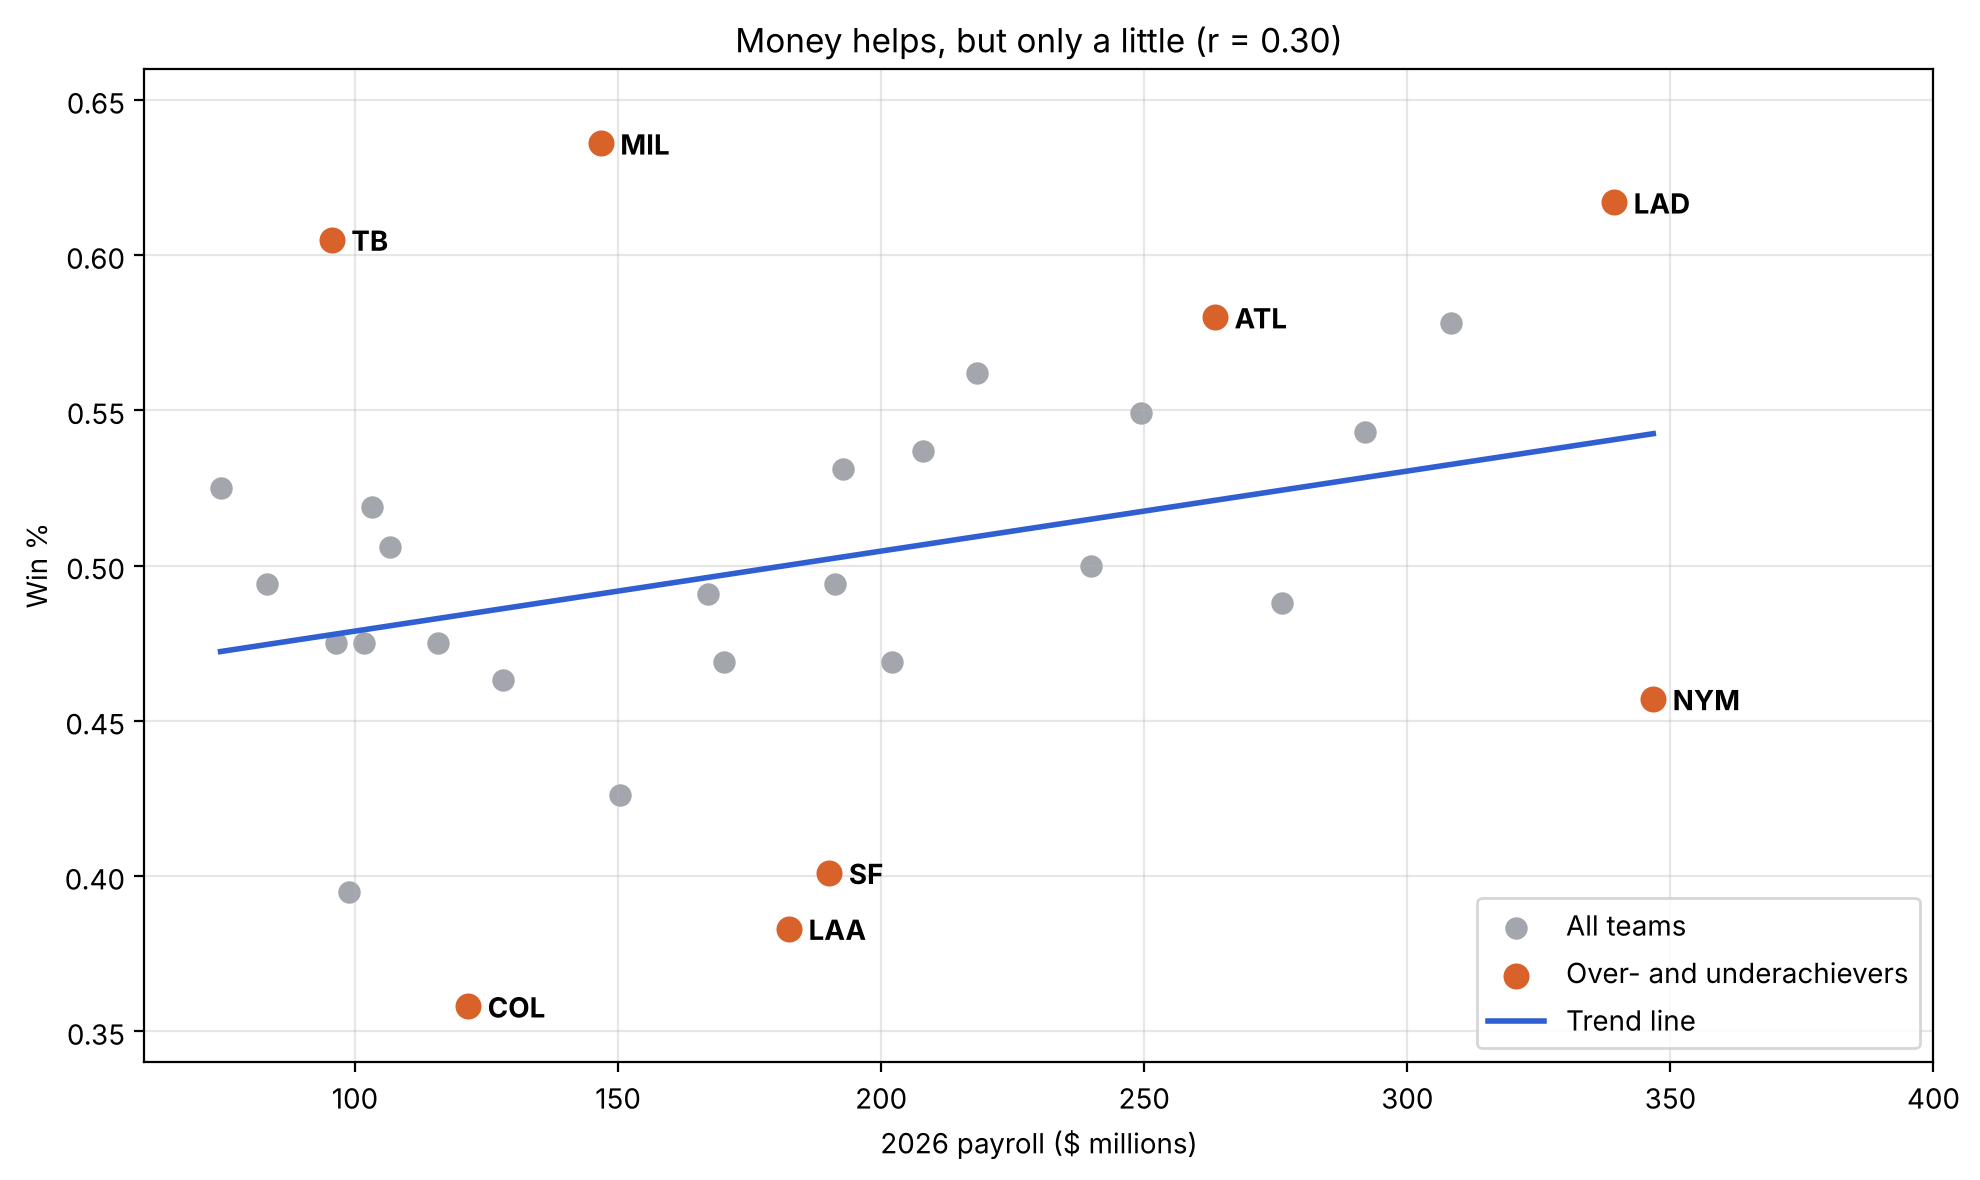

In [7]:
highlight = pd.concat([overachievers, underachievers])

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(teams["payroll_m"], teams["win_pct"], color="#A3A6AD", s=50, label="All teams")
ax.scatter(highlight["payroll_m"], highlight["win_pct"], color="#D9622B", s=70, zorder=3,
           label="Over- and underachievers")
for _, row in highlight.iterrows():
    ax.annotate(row["team"], (row["payroll_m"], row["win_pct"]), xytext=(7, -4),
                textcoords="offset points", fontweight="bold")

x_line = np.linspace(teams["payroll_m"].min(), teams["payroll_m"].max(), 100)
y_line = model.params["Intercept"] + model.params["payroll_m"] * x_line
ax.plot(x_line, y_line, color="#2F5FD0", linewidth=2, label="Trend line")

ax.set_title(f"Money helps, but only a little (r = {r:.2f})")
ax.set_xlabel("2026 payroll ($ millions)")
ax.set_ylabel("Win %")
ax.set_xlim(60, 400)
ax.set_ylim(0.34, 0.66)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(IMG_DIR / "payroll_vs_win_pct.png", dpi=200)
plt.show()

### What one win cost each team

In [8]:
teams["cost_per_win_m"] = teams["payroll_m"] / teams["wins"]
league_avg = teams["total_payroll"].sum() / teams["wins"].sum() / 1e6
print(f"League average: ${league_avg:.2f}M per win (total payroll / total wins)")

cost_table = teams.sort_values("cost_per_win_m")[["team", "payroll_m", "wins", "cost_per_win_m"]]
print("\nCheapest wins:")
display(cost_table.head(3).round(2))
print("Most expensive wins:")
display(cost_table.tail(3).round(2))

cle = teams.loc[teams["team"] == "CLE", "cost_per_win_m"].iloc[0]
nym = teams.loc[teams["team"] == "NYM", "cost_per_win_m"].iloc[0]
print(f"The Mets paid {nym / league_avg:.1f}x the league average and {nym / cle:.1f}x what Cleveland paid per win")

League average: $2.25M per win (total payroll / total wins)

Cheapest wins:


,team,payroll_m,wins,cost_per_win_m
29,CLE,74.46,85,0.88
27,TB,95.62,98,0.98
28,MIA,83.30,80,1.04


Most expensive wins:


,team,payroll_m,wins,cost_per_win_m
1,LAD,339.32,100,3.39
4,TOR,276.13,79,3.50
0,NYM,346.74,74,4.69


The Mets paid 2.1x the league average and 5.3x what Cleveland paid per win


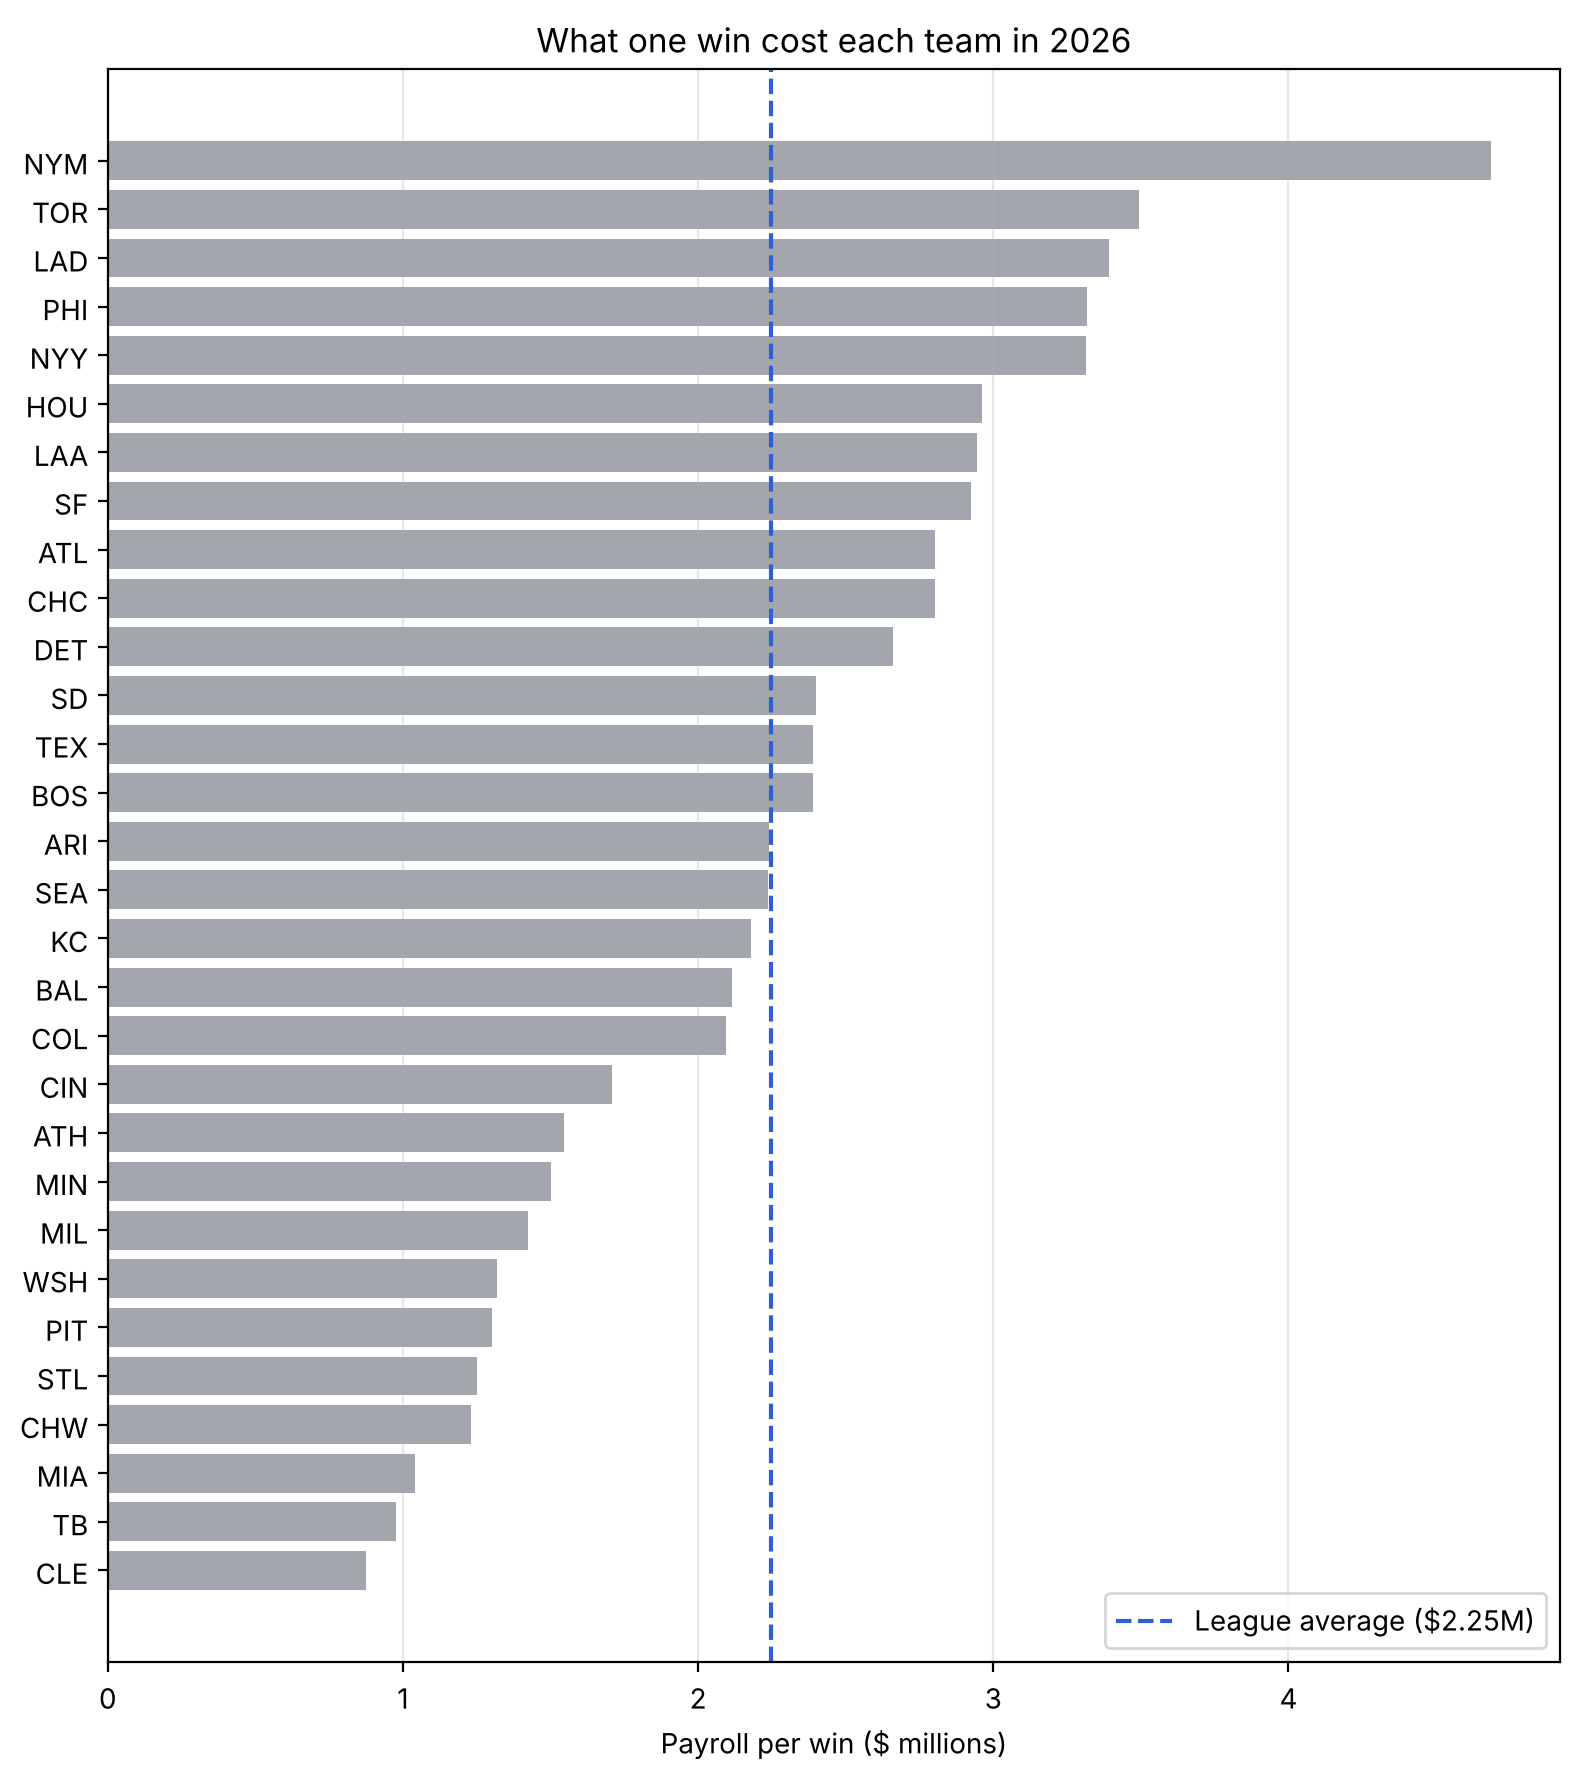

In [9]:
plot_df = teams.sort_values("cost_per_win_m")
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(plot_df["team"], plot_df["cost_per_win_m"], color="#A3A6AD")
ax.axvline(league_avg, color="#2F5FD0", linestyle="--", label=f"League average (${league_avg:.2f}M)")
ax.set_title("What one win cost each team in 2026")
ax.set_xlabel("Payroll per win ($ millions)")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(IMG_DIR / "cost_per_win.png", dpi=200)
plt.show()

*What this shows:* the cheapest wins came from the lowest payrolls (Cleveland, Tampa Bay, Miami) and the most expensive from the highest (the Mets, Toronto, the Dodgers). Over- and underachievers show up at every spending level.